# 04 · Baselines: how predictable is delay, and how early can a bad day be spotted?

Two questions, both answered with the simplest possible methods first, scored on a
held-out period, with honest error metrics. Nothing fancier is added unless it clearly
beats the baseline on the hold-out.

**Forecasting.** A train is at stop *k* with signed delay *d_k*. Predict its delay *h*
stops later. Training period: clean weekdays up to 2026-06-30. Hold-out: clean weekdays
from 2026-07-01 (July, August, September, October 2026 — 46 days, two of them with a
different timetable version).

**Anomaly detection.** How early in a bad day could a simple rolling rule have raised an
alert, and how often would it fire on a normal day?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import q, connect
from viz import BLUE, ORANGE, AQUA, VIOLET, RED, MUTED, GRID, SEQ, DIR_COLOR, note

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 120)
con = connect()
qq = lambda s: q(s, con)
SPLIT = "2026-07-01"

## 1. Build (origin stop, target stop) pairs

One row per trip-day and pair of observed stops *h* ∈ {1, 3, 5, 8} apart. The row
carries the delay at the origin stop, the delay of the previous same-direction train at
that stop (the "leader"), and the target delay.

In [2]:
pairs = qq(f"""
with c as (
  select date, trip_id, direction, service, station, stop_id, stop_rank, sched_hour, sched_ts, delay_signed,
         lag(delay_signed) over (partition by date, stop_id order by sched_ts) leader_delay,
         epoch(sched_ts - lag(sched_ts) over (partition by date, stop_id order by sched_ts))/60 leader_headway
  from clean where weekday)
select a.date, a.trip_id, a.direction, a.service, a.station, a.stop_rank, a.sched_hour, a.delay_signed d0,
       a.leader_delay, a.leader_headway, b.delay_signed d1, b.stop_rank - a.stop_rank h, b.station target_station,
       a.date < '{SPLIT}' as train
from c a join c b on a.date=b.date and a.trip_id=b.trip_id and b.stop_rank - a.stop_rank in (1,3,5,8)
""")
pairs["late_target"] = pairs.d1 > 4
print(len(pairs), "pairs;", pairs.train.mean().round(3), "share in training;", pairs[~pairs.train].date.nunique(), "hold-out days")

991089 pairs; 0.823 share in training; 47 hold-out days


## 2. Baselines

* **schedule**: predict 0 (the train will be on time).
* **persistence**: predict *d_k*.
* **train history**: the training-period median delay of this train number at the target stop, ignoring the present.
* **persistence + profile**: *d_k* plus the training-period median change in delay from this stop over *h* stops, for this train number (falling back to direction × station × *h* when the train has < 30 training runs).
* **persistence + profile + leader**: the above, plus a shrinkage term towards the leader's delay when the leader is late and the headway is short. One tuned coefficient, fitted on the training period only.

In [3]:
tr, te = pairs[pairs.train], pairs[~pairs.train]
# train-history baseline
hist_med = tr.groupby(["trip_id", "target_station"]).d1.median().rename("hist_med")
# profile: median accrual by train & origin stop & h, fallback direction/station/h
prof_train = tr.assign(dd=tr.d1 - tr.d0).groupby(["trip_id", "station", "h"]).dd.agg(["median", "size"])
prof_gen = tr.assign(dd=tr.d1 - tr.d0).groupby(["direction", "station", "h"]).dd.median().rename("prof_gen")

def predict(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["p_schedule"] = 0.0
    out["p_persist"] = out.d0
    out = out.merge(hist_med, left_on=["trip_id", "target_station"], right_index=True, how="left")
    out["p_hist"] = out.hist_med.fillna(0)
    out = out.merge(prof_train, left_on=["trip_id", "station", "h"], right_index=True, how="left")
    out = out.merge(prof_gen, left_on=["direction", "station", "h"], right_index=True, how="left")
    prof = np.where(out["size"].fillna(0) >= 30, out["median"], out.prof_gen)
    out["p_profile"] = out.d0 + np.nan_to_num(prof)
    # leader term: how much of the leader's excess over the headway the follower is expected to inherit
    excess = np.clip(out.leader_delay.fillna(0) - out.leader_headway.fillna(99), 0, None)
    out["excess"] = excess
    return out

trp, tep = predict(tr), predict(te)
# fit the one leader coefficient on training residuals (least squares through the origin)
resid = trp.d1 - trp.p_profile
beta = float((resid * trp.excess).sum() / (trp.excess ** 2).sum())
print(f"leader coefficient beta = {beta:.2f}")
for d in (trp, tep):
    d["p_leader"] = d.p_profile + beta * d.excess

leader coefficient beta = 0.04


In [4]:
def score(df: pd.DataFrame, cols) -> pd.DataFrame:
    rows = []
    for h, g in df.groupby("h"):
        for c in cols:
            err = g[c] - g.d1
            rows.append({"h": h, "model": c.replace("p_", ""), "n": len(g), "MAE": err.abs().mean(), "RMSE": np.sqrt((err**2).mean()),
                         "MAE_when_late_now": err[g.d0 > 4].abs().mean(), "n_late_now": int((g.d0 > 4).sum())})
    return pd.DataFrame(rows)

cols = ["p_schedule", "p_persist", "p_hist", "p_profile", "p_leader"]
sc = score(tep, cols)
sc.pivot(index="h", columns="model", values="MAE").round(2)[["schedule", "persist", "hist", "profile", "leader"]]

model,schedule,persist,hist,profile,leader
h,,,,,
1,1.47,0.62,1.26,0.45,0.45
3,1.53,0.79,1.31,0.64,0.64
5,1.61,0.98,1.37,0.78,0.78
8,1.67,1.12,1.42,0.95,0.95


In [5]:
sc.pivot(index="h", columns="model", values="MAE_when_late_now").round(2)[["schedule", "persist", "hist", "profile", "leader"]]

model,schedule,persist,hist,profile,leader
h,,,,,
1,9.62,0.77,8.78,0.57,0.57
3,9.76,1.18,8.92,1.03,1.02
5,10.13,1.59,9.25,1.43,1.42
8,10.30,2.02,9.47,1.92,1.92


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


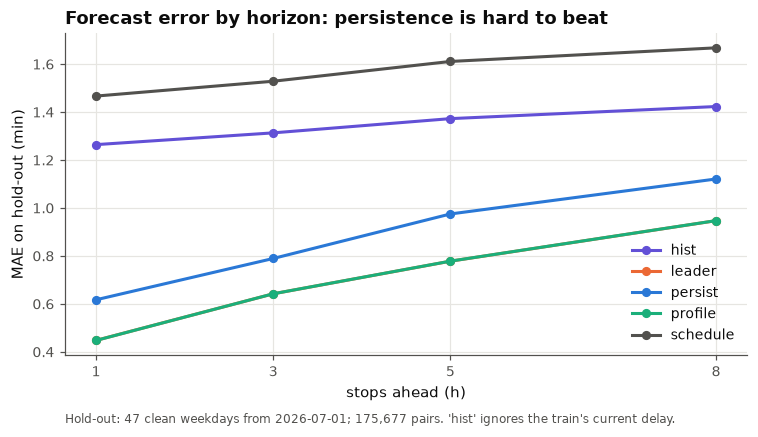

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
colors = {"schedule": MUTED, "persist": BLUE, "hist": VIOLET, "profile": AQUA, "leader": ORANGE}
for m, g in sc.groupby("model"):
    ax.plot(g.h, g.MAE, marker="o", color=colors[m], label=m)
ax.set_xlabel("stops ahead (h)"); ax.set_ylabel("MAE on hold-out (min)"); ax.set_xticks([1, 3, 5, 8])
ax.set_title("Forecast error by horizon: persistence is hard to beat"); ax.legend()
note(ax, f"Hold-out: {te.date.nunique()} clean weekdays from {SPLIT}; {len(te):,} pairs. 'hist' ignores the train's current delay.")
plt.show()

Persistence alone removes 40% of the schedule's error at five stops ahead (MAE 0.98 vs
1.61 min), and knowing the train's current delay matters far more than knowing its
history (the train-history baseline barely beats the schedule). Adding the median accrual
profile removes another 20% (0.78 min): it corrects the known tight and loose segments.
The leader term fits a coefficient of 0.04 and changes nothing measurable: by the time
a follower is caught behind a late leader, its *own* current delay already says so.

### Classification: will the train be late (> 4 min) h stops from now?

In [7]:
def cls(df, col, thr=4.0):
    pred, act = df[col] > thr, df.late_target
    tp = (pred & act).sum(); fp = (pred & ~act).sum(); fn = (~pred & act).sum()
    return pd.Series({"precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1), "base_rate": act.mean()})

rows = []
for h, g in tep.groupby("h"):
    for c in ["p_persist", "p_profile", "p_leader"]:
        rows.append(cls(g, c).rename(f"h={h} {c.replace('p_','')}"))
pd.DataFrame(rows).round(3)

,precision,recall,base_rate
h=1 persist,0.907,0.827,0.061
h=1 profile,0.908,0.874,0.061
h=1 leader,0.907,0.874,0.061
h=3 persist,0.890,0.686,0.065
h=3 profile,0.885,0.735,0.065
h=3 leader,0.884,0.735,0.065
h=5 persist,0.878,0.578,0.070
h=5 profile,0.858,0.640,0.070
h=5 leader,0.858,0.640,0.070
h=8 persist,0.871,0.457,0.076


### Is the hold-out representative? Error by month
July–August 2026 were unusually calm months; September and October were not. The
ranking of the baselines is the same in every month.

In [8]:
tep["month"] = pd.to_datetime(tep.date).dt.to_period("M").astype(str)
g5 = tep[tep.h == 5]
pd.DataFrame({c.replace("p_", ""): (g5[c] - g5.d1).abs().groupby(g5.month).mean() for c in cols}).round(2)

,schedule,persist,hist,profile,leader
month,,,,,
2026-07,1.37,0.92,1.12,0.72,0.72
2026-08,1.38,0.92,1.15,0.72,0.72
2026-09,2.11,1.13,1.91,0.95,0.95
2026-10,1.96,1.01,1.67,0.80,0.80


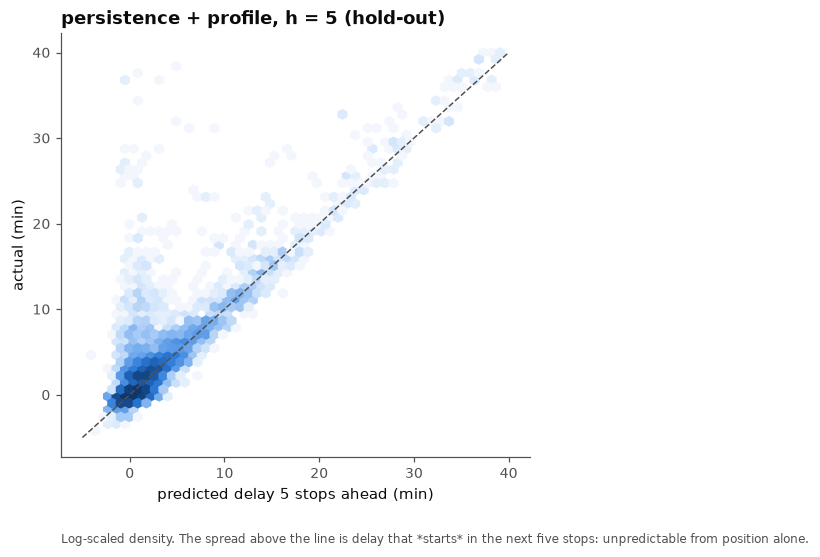

In [9]:
# Calibration-style view for h=5: predicted vs actual, persistence+profile
g = tep[tep.h == 5]
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.hexbin(g.p_profile, g.d1, gridsize=50, extent=(-5, 40, -5, 40), cmap=SEQ, bins="log", mincnt=1)
ax.plot([-5, 40], [-5, 40], color=MUTED, ls="--", lw=1); ax.grid(False)
ax.set_xlabel("predicted delay 5 stops ahead (min)"); ax.set_ylabel("actual (min)"); ax.set_title("persistence + profile, h = 5 (hold-out)")
note(ax, "Log-scaled density. The spread above the line is delay that *starts* in the next five stops: unpredictable from position alone.")
plt.show()

## 3. Anomaly detection: how early could a bad day be flagged?

A rule anyone could run every five minutes: *in the last 60 minutes of scheduled calls,
more than X% of arrivals were > 4 minutes late, with at least 20 arrivals*. We score
it against the day's eventual severity (share of arrivals > 15 min late, from notebook
03), on all clean days, to see when it would fire on the 20 worst days and how often it
fires on ordinary days.

In [10]:
arr = qq("select date, sched_ts, delay_signed > 4 as late from clean where sched_ts is not null order by date, sched_ts")
arr["t"] = pd.to_datetime(arr.sched_ts)
sev = qq("select date, avg(late15::int) late15 from clean group by 1").set_index("date").late15
worst20 = set(sev.sort_values(ascending=False).head(20).index)

def first_alert(day: pd.DataFrame, thr: float, window="60min", min_n=20):
    s = day.set_index("t").late.astype(float)
    roll_mean = s.rolling(window).mean(); roll_n = s.rolling(window).count()
    hit = (roll_mean > thr) & (roll_n >= min_n)
    return hit.idxmax() if hit.any() else pd.NaT

rows = []
for thr in (0.3, 0.5, 0.7):
    alerts = {d: first_alert(g, thr) for d, g in arr.groupby("date")}
    a = pd.Series(alerts)
    normal = [d for d in a.index if d not in worst20]
    rows.append({"threshold": thr, "worst20_detected": sum(pd.notna(a[d]) for d in worst20),
                 "normal_days_alerted": sum(pd.notna(a[d]) for d in normal), "normal_days": len(normal),
                 "false_alarm_rate": sum(pd.notna(a[d]) for d in normal) / len(normal)})
pd.DataFrame(rows).round(3)

,threshold,worst20_detected,normal_days_alerted,normal_days,false_alarm_rate
0,0.3,20,163,360,0.453
1,0.5,19,48,360,0.133
2,0.7,14,8,360,0.022


In [11]:
alerts = pd.Series({d: first_alert(g, 0.5) for d, g in arr.groupby("date")})
tbl = pd.DataFrame({"late15_share": sev, "first_alert": alerts}).loc[sorted(worst20, key=lambda d: -sev[d])]
# the hour at which the day's late share first exceeded 50%, for reference
tbl["alert_time"] = tbl.first_alert.dt.strftime("%H:%M")
tbl[["late15_share", "alert_time"]].round(3)

,late15_share,alert_time
2025-11-06,0.241,16:25
2026-01-03,0.193,17:16
2025-10-24,0.183,17:00
2025-08-18,0.169,06:27
2026-01-11,0.147,11:54
2026-03-19,0.144,17:15
2025-08-27,0.111,18:01
2026-03-14,0.104,16:35
2025-10-04,0.090,22:40
2026-06-22,0.088,08:51


At a 50% threshold the rule catches 19 of the 20 worst days and fires on 13% of the
other days; at 70% it catches 14 of 20 with a 2% false-alarm rate. Most "false" alarms are
days with a real but short disruption, so the trade-off is about how small an incident is
worth a notification. The detection time is typically 30–60 minutes after the first
delayed arrivals of the incident: the inherent latency of a rule that waits for 20 arrivals.

For a per-train anomaly score the same logic applies: a train's delay at its last stop
compared with its own history is informative (notebook 02's league table), but the
natural unit of a Caltrain disruption is the hour, not the train.

## 4. What a model would need to beat these

* The forecasting residual is dominated by *onset*: delays that begin after the
  prediction is made. Position data cannot see them coming. 511's TripUpdates feed
  (per-stop predicted delays) or ServiceAlerts would be the first things to add.
* The leader/headway interaction is real but small in MAE terms because serious leader
  delays are rare; it matters for the *late/not late* decision on Express trains.
* Anything learned (gradient boosting on train, stop, hour, leader, current delay) should
  be judged against `persistence + profile` on this same hold-out, not against the schedule.